# Retail Customer-Month Dataset Exploration
One row represents one customer at one monthly snapshot. Historical features use only information before the snapshot; targets describe the month beginning at the snapshot.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

candidate = Path.cwd()
PROJECT_ROOT = candidate if (candidate / 'data').exists() else candidate.parent
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'customer_monthly_ml.csv'
data = pd.read_csv(DATA_PATH, parse_dates=['snapshot_date'])
data.head()

,customer_id,snapshot_date,tenure_days,orders_last_90d,spend_last_90d_lkr,avg_order_value_last_90d_lkr,order_value_std_last_90d_lkr,days_since_last_purchase,has_previous_purchase,next_month_spend_lkr,will_purchase_next_month
0,C0001,2025-04-01,424,2,17428.30,8714.15,2150.96,19.0,1,0.00,0
1,C0002,2025-04-01,163,4,8259.83,2064.96,448.74,21.0,1,4564.19,1
2,C0003,2025-04-01,228,14,87429.64,6244.97,3131.16,6.0,1,35779.84,1
3,C0004,2025-04-01,373,7,17558.55,2508.36,828.14,32.0,1,4063.69,1
4,C0005,2025-04-01,197,2,4516.73,2258.36,729.16,55.0,1,3698.67,1


## Shape, types, missing values, and time coverage
Blank `days_since_last_purchase` means that no earlier purchase exists; it is not automatically a bad record.

In [2]:
print('Shape:', data.shape)
display(data.dtypes.to_frame('dtype'))
display(data.isna().sum().to_frame('missing'))
print('Snapshots:', data['snapshot_date'].min(), 'to', data['snapshot_date'].max())
display(data['snapshot_date'].value_counts().sort_index().to_frame('rows'))

Shape: (12000, 11)


,dtype
customer_id,object
snapshot_date,datetime64[ns]
tenure_days,int64
orders_last_90d,int64
spend_last_90d_lkr,float64
avg_order_value_last_90d_lkr,float64
order_value_std_last_90d_lkr,float64
days_since_last_purchase,float64
has_previous_purchase,int64
next_month_spend_lkr,float64


,missing
customer_id,0
snapshot_date,0
tenure_days,0
orders_last_90d,0
spend_last_90d_lkr,0
avg_order_value_last_90d_lkr,0
order_value_std_last_90d_lkr,0
days_since_last_purchase,555
has_previous_purchase,0
next_month_spend_lkr,0


Snapshots: 2025-04-01 00:00:00 to 2026-03-01 00:00:00


,rows
snapshot_date,
2025-04-01,1000
2025-05-01,1000
2025-06-01,1000
2025-07-01,1000
2025-08-01,1000
2025-09-01,1000
2025-10-01,1000
2025-11-01,1000
2025-12-01,1000


## Targets
The regression target keeps zero-spend customers. The classification target is 1 exactly when target-month spend is positive.

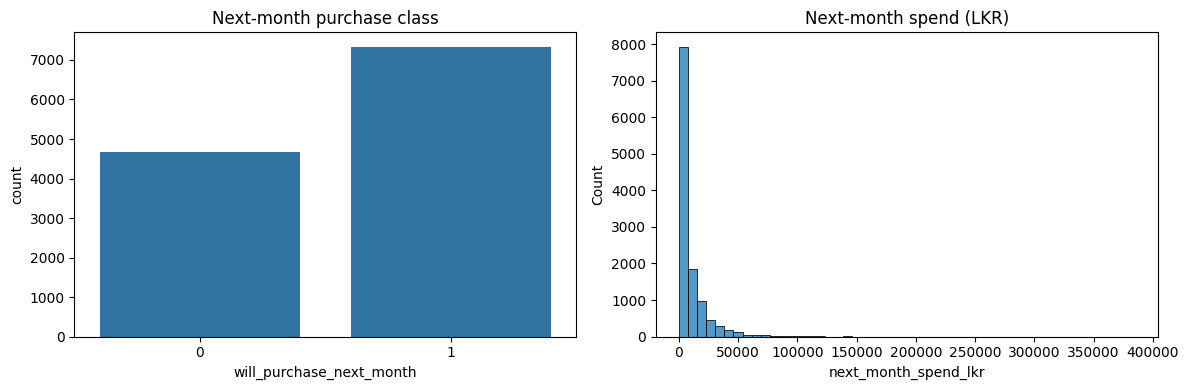

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x='will_purchase_next_month', ax=axes[0])
axes[0].set_title('Next-month purchase class')
sns.histplot(data=data, x='next_month_spend_lkr', bins=50, ax=axes[1])
axes[1].set_title('Next-month spend (LKR)')
plt.tight_layout()
plt.show()

## Historical feature distributions and correlation

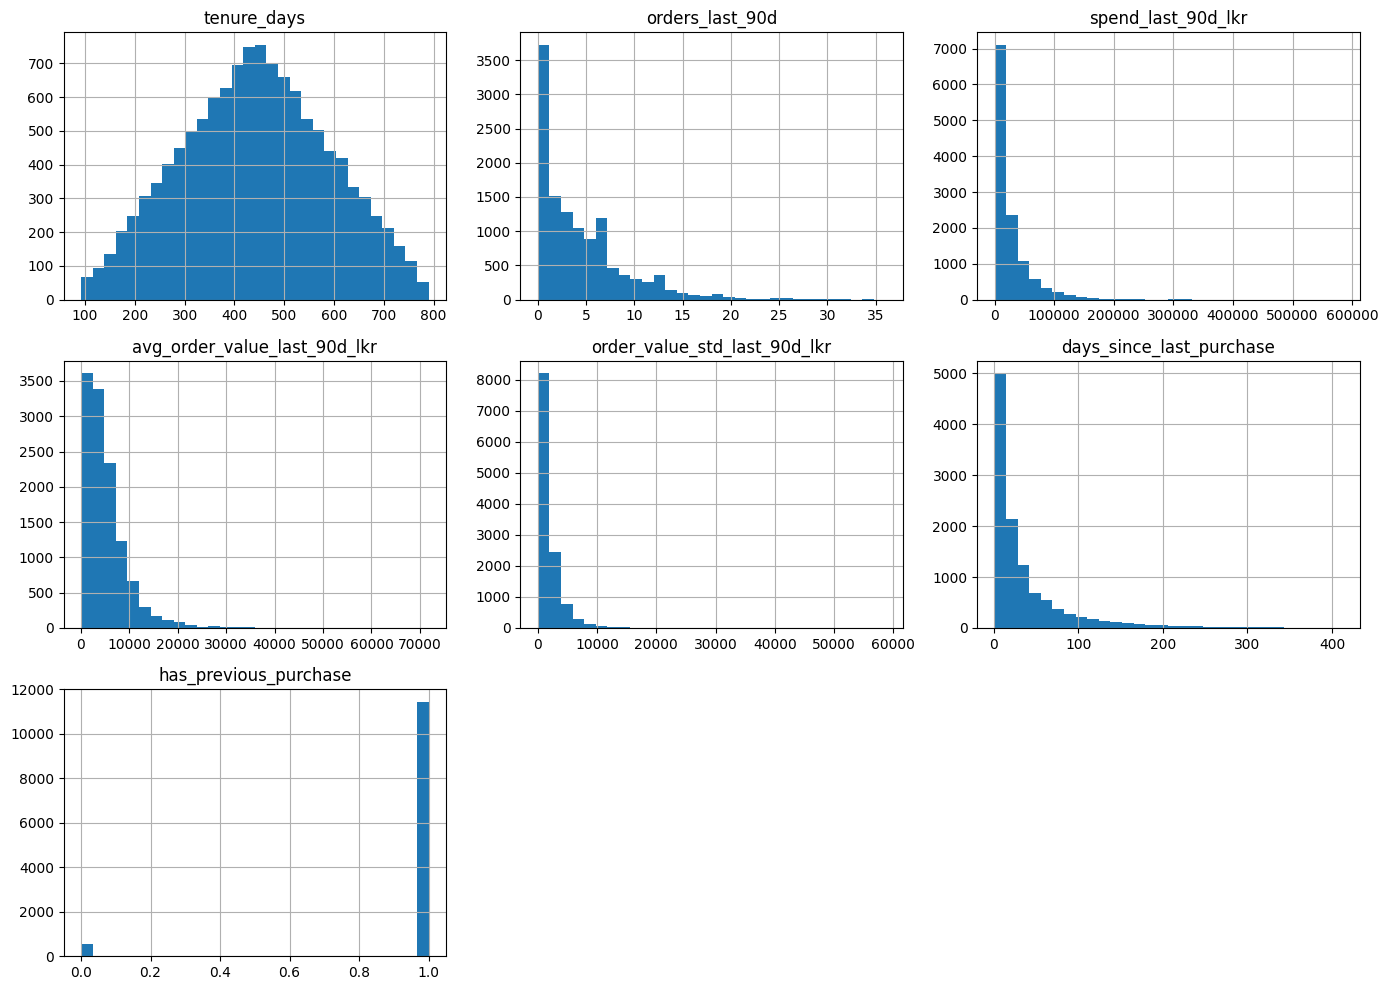

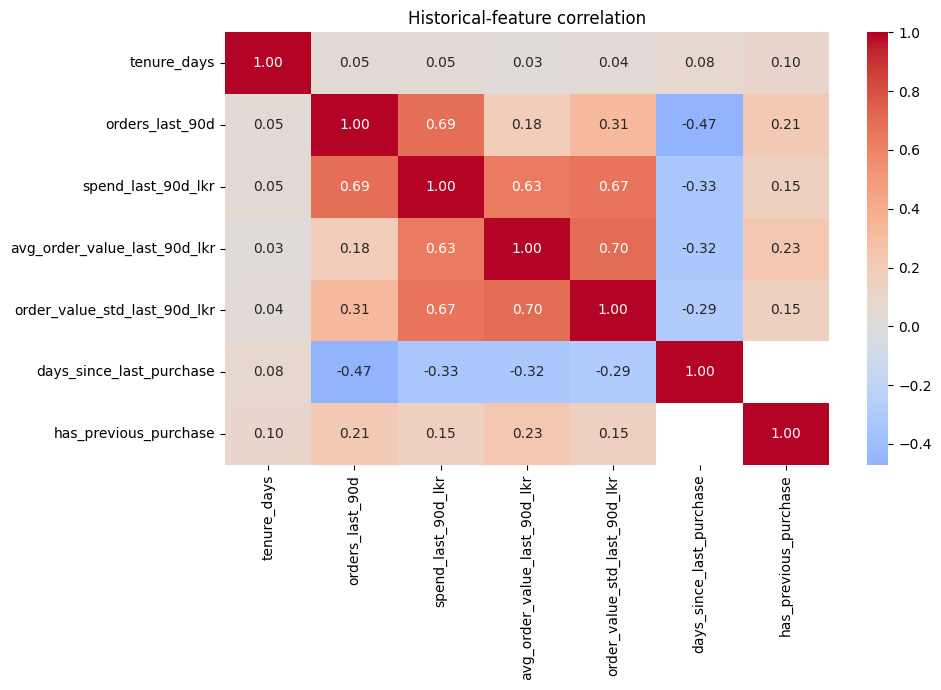

In [4]:
FEATURES = [
    'tenure_days', 'orders_last_90d', 'spend_last_90d_lkr',
    'avg_order_value_last_90d_lkr', 'order_value_std_last_90d_lkr',
    'days_since_last_purchase', 'has_previous_purchase'
]
data[FEATURES].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 7))
sns.heatmap(data[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Historical-feature correlation')
plt.tight_layout()
plt.show()

## Repeated customers and chronological evaluation
Customers occur in multiple snapshots, so random row splitting could mix future and past rows. The project trains on 2025-04 through 2025-11, validates on 2025-12 through 2026-01, and tests on 2026-02 through 2026-03. This estimates rolling future outcomes for existing customers, not entirely unseen customers.

Model inputs use only the seven historical features above. `customer_id` and `snapshot_date` are metadata. Both `next_month_spend_lkr` and `will_purchase_next_month` are targets and both must be excluded from X to prevent leakage.

In [5]:
print('Unique customers:', data['customer_id'].nunique())
print('Rows per customer summary:')
display(data.groupby('customer_id').size().describe())
display(data.groupby('snapshot_date')[['next_month_spend_lkr', 'will_purchase_next_month']].agg(['mean', 'median']))

Unique customers: 1000
Rows per customer summary:


count    1000.0
mean       12.0
std         0.0
min        12.0
25%        12.0
50%        12.0
75%        12.0
max        12.0
dtype: float64

next_month_spend_lkr           will_purchase_next_month       
                              mean    median                     mean median
snapshot_date                                                               
2025-04-01             11410.36261  5657.030                    0.698    1.0
2025-05-01              8839.02171  3247.905                    0.607    1.0
2025-06-01              8508.96162  3383.355                    0.630    1.0
2025-07-01              7856.84040  3142.890                    0.584    1.0
2025-08-01              8223.25874  2703.900                    0.584    1.0
2025-09-01              8089.48879  3287.685                    0.602    1.0
2025-10-01              7602.15266  2828.005                    0.577    1.0
2025-11-01              8437.92061  3075.150                    0.598    1.0
2025-12-01             11332.46065  4504.800                    0.659    1.0
2026-01-01              8235.68645  3205.820                    0.591    1.0
2026-02-01              7912.96001  3161.365                    0.607    1.0
2026-03-01              7678.65562  2693.825                    0.596    1.0